In [59]:
"""
=============================================================================
FIFA PLAYER DATASET — FULL DATA CLEANING & FEATURE ENGINEERING PIPELINE
=============================================================================
Target Variable  : wage_eur
Goal             : Prepare a 100% numeric, zero-null DataFrame for
                   Linear Regression wage prediction.

Pipeline Stages
---------------
0.  Load data
1.  Drop identity / junk columns
2.  Drop the "89+2" position-rating columns
3.  Drop high-NaN summary float stats (pace, gk_diving, …)
4.  Handle the Goalkeeper ↔ Outfield NaN split
5.  Fill release_clause_eur with median
6.  Convert contract_valid_until → years_until_expiration
7.  Encode body_type  (ordinal 1-3)
8.  Encode preferred_foot (binary 0/1)
9.  Encode work_rate  (split + ordinal 1-3)
10. Encode player_traits → good_traits_count / bad_traits_count
11. Encode nationality  (Top-10 + Other → one-hot)
12. Encode club         (Elite-15 + Other → one-hot)
13. Encode player_positions → role columns (Attack/Mid/Def/GK)
14. Encode team_position → is_starter (binary)
15. Encode loaned_from  → is_on_loan (binary)
16. Drop leftover raw text columns
17. Final audit — confirm 100% numeric, zero nulls
=============================================================================
"""

import pandas as pd
import numpy as np

# ── 0. LOAD DATA ─────────────────────────────────────────────────────────────
# Change the filename / path to match your local file
df = pd.read_excel("FIFA2020_dataset.xlsx")   # or pd.read_excel("FIFA2020_dataset.xlsx")
print(f"[LOAD] Shape after load : {df.shape}")


# ── 1. DROP IDENTITY / JUNK COLUMNS ──────────────────────────────────────────
#   • sofifa_id, player_url  → just database IDs / URLs
#   • short_name, long_name  → text identifiers
#   • dob                    → age already exists
#   • real_face              → video-game aesthetic flag
#   • team_jersey_number     → jersey number ≠ performance
#   • player_tags            → >91 % missing → noise
#   • nation_position        → >93 % missing → noise
#   • nation_jersey_number   → >93 % missing → noise
#   • joined                 → raw date; no reliable relative value
identity_junk = [
    "sofifa_id", "player_url", "short_name", "long_name",
    "dob", "real_face", "team_jersey_number",
    "player_tags", "nation_position", "nation_jersey_number",
    "joined",
]
df.drop(columns=identity_junk, errors="ignore", inplace=True)
print(f"[1] After dropping identity/junk cols : {df.shape}")


# ── 2. DROP "89+2" POSITION-RATING COLUMNS ───────────────────────────────────
#   These 26 columns (ls, st, rs, lw, …) contain strings like "89+2".
#   They are fully redundant with the raw stat columns already present.
pos_rating_cols = [
    "ls", "st", "rs", "lw", "lf", "cf", "rf", "rw",
    "lam", "cam", "ram", "lm", "lcm", "cm", "rcm", "rm",
    "lwb", "ldm", "cdm", "rdm", "rwb",
    "lb", "lcb", "cb", "rcb", "rb",
]
df.drop(columns=pos_rating_cols, errors="ignore", inplace=True)
print(f"[2] After dropping position-rating cols : {df.shape}")


# ── 3. DROP HIGH-NaN SUMMARY FLOAT STATS ─────────────────────────────────────
#   pace / shooting / … → only populated for outfield players (~11 % missing)
#   gk_diving / …       → only populated for goalkeepers  (~89 % missing)
#   We KEEP the granular int64 attributes (attacking_finishing, goalkeeping_diving…)
#   because they carry realistic values for ALL players.
summary_floats = [
    "pace", "shooting", "passing", "dribbling", "defending", "physic",
    "gk_diving", "gk_handling", "gk_kicking",
    "gk_reflexes", "gk_speed", "gk_positioning",
]
df.drop(columns=summary_floats, errors="ignore", inplace=True)
print(f"[3] After dropping summary float stats  : {df.shape}")


# ── 4. FILL GRANULAR SKILL NaNs WITH 0 ───────────────────────────────────────
#   The int64 attribute columns (e.g. goalkeeping_diving) are NaN only for
#   a small subset. Filling with 0 is logically correct:
#   an attacker's "goalkeeping_diving" contribution is effectively zero.
granular_skills = [
    "attacking_crossing", "attacking_finishing", "attacking_heading_accuracy",
    "attacking_short_passing", "attacking_volleys",
    "skill_dribbling", "skill_curve", "skill_fk_accuracy",
    "skill_long_passing", "skill_ball_control",
    "movement_acceleration", "movement_sprint_speed", "movement_agility",
    "movement_reactions", "movement_balance",
    "power_shot_power", "power_jumping", "power_stamina",
    "power_strength", "power_long_shots",
    "mentality_aggression", "mentality_interceptions",
    "mentality_positioning", "mentality_vision",
    "mentality_penalties", "mentality_composure",
    "defending_marking", "defending_standing_tackle", "defending_sliding_tackle",
    "goalkeeping_diving", "goalkeeping_handling", "goalkeeping_kicking",
    "goalkeeping_positioning", "goalkeeping_reflexes",
]
existing_skills = [c for c in granular_skills if c in df.columns]
df[existing_skills] = df[existing_skills].fillna(0)
print(f"[4] Granular skill NaNs filled with 0.")


# ── 5. FILL release_clause_eur WITH MEDIAN ───────────────────────────────────
#   Distribution is heavily right-skewed (superstar outliers inflate the mean).
#   Using the median keeps "normal" players realistic.
if "release_clause_eur" in df.columns:
    median_rc = df["release_clause_eur"].median()
    df["release_clause_eur"] = (
        df["release_clause_eur"]
        .fillna(median_rc)
        .astype(float)
    )
    print(f"[5] release_clause_eur nulls filled with median = {median_rc:,.0f}")


# ── 6. CONTRACT → YEARS UNTIL EXPIRATION ─────────────────────────────────────
#   Converts a raw year (e.g. 2024) into a forward-looking numeric feature.
#   Players with expired / missing contracts → 0.
CURRENT_YEAR = 2020
if "contract_valid_until" in df.columns:
    df["contract_valid_until"] = pd.to_numeric(
        df["contract_valid_until"], errors="coerce"
    )
    df["years_until_expiration"] = (
        (df["contract_valid_until"] - CURRENT_YEAR)
        .clip(lower=0)
        .fillna(0)
        .astype(int)
    )
    df.drop(columns=["contract_valid_until"], inplace=True)
    print("[6] contract_valid_until → years_until_expiration (int).")


# ── 7. ENCODE body_type — ORDINAL 1-3 ────────────────────────────────────────
#   Some cells contain player names used as body-type proxies in the FIFA engine.
#   We remap everything to three physical categories, then to 1 / 2 / 3.
#   Stocky = 3 (strongest/heaviest build)
if "body_type" in df.columns:
    body_map = {
        # Lean builds
        "Lean": 1, "Neymar": 1, "Messi": 1,
        # Normal builds
        "Normal": 2, "Courtois": 2, "Shaqiri": 2, "PLAYER_BODY_TYPE_25": 2,
        # Stocky builds
        "Stocky": 3, "C. Ronaldo": 3, "Akinfenwa": 3,
    }
    df["body_type_num"] = (
        df["body_type"].map(body_map).fillna(2).astype(int)
    )
    df.drop(columns=["body_type"], inplace=True)
    print("[7] body_type → body_type_num (1=Lean, 2=Normal, 3=Stocky).")


# ── 8. ENCODE preferred_foot — BINARY 0/1 ────────────────────────────────────
#   Left = 0 (majority baseline for Linear Regression)
#   Right = 1 (the "special condition" flag)
#   NOTE: column is DROPPED to avoid Linear Regression bias
#          (a regression model may falsely treat 1 > 0 as "better").
if "preferred_foot" in df.columns:
    foot_map = {"Right": 1, "Left": 0}
    df["preferred_foot"] = (
        df["preferred_foot"].map(foot_map).fillna(1).astype(int)
    )
    # Final decision: drop to keep the model performance-focused and bias-free
    df.drop(columns=["preferred_foot"], inplace=True)
    print("[8] preferred_foot encoded then dropped (bias prevention).")


# ── 9. ENCODE work_rate — SPLIT + ORDINAL ────────────────────────────────────
#   'High/Medium' → work_rate_att = 3, work_rate_def = 2
#   Scale: Low=1, Medium=2, High=3
if "work_rate" in df.columns:
    rate_map = {"High": 3, "Medium": 2, "Low": 1}
    split = df["work_rate"].str.split("/", expand=True)
    df["work_rate_att"] = split[0].str.strip().map(rate_map).fillna(2).astype(int)
    df["work_rate_def"] = split[1].str.strip().map(rate_map).fillna(2).astype(int)
    df.drop(columns=["work_rate"], inplace=True)
    print("[9] work_rate split → work_rate_att / work_rate_def (1-3 ordinal).")


# ── 10. PARSE player_traits → GOOD / BAD COUNTS ──────────────────────────────
#   "Bad" traits are behavioral risks that may suppress wages or club value.
#   Everything else is treated as a positive / skill trait.
BAD_TRAITS = {
    "Argues with Officials", "Selfish", "Diver",
    "Injury Prone", "Inflexible", "Dives Into Tackles",
}

def count_traits(text):
    if pd.isna(text) or text == "":
        return 0, 0
    items = [t.strip() for t in text.split(",")]
    bad  = sum(1 for t in items if t in BAD_TRAITS)
    good = len(items) - bad
    return good, bad

if "player_traits" in df.columns:
    df[["good_traits_count", "bad_traits_count"]] = (
        df["player_traits"].apply(lambda x: pd.Series(count_traits(x)))
    )
    df.drop(columns=["player_traits"], inplace=True)
    print("[10] player_traits → good_traits_count / bad_traits_count.")


# ── 11. ENCODE nationality — TOP-10 + OTHER → ONE-HOT ────────────────────────
#   162 distinct values → keep the 10 most frequent as individual columns;
#   everything else collapses into 'Other'. This prevents column bloat and
#   removes noise from countries with only 1-2 players.
if "nationality" in df.columns:
    top10 = df["nationality"].value_counts().nlargest(10).index.tolist()
    df["nat_grp"] = df["nationality"].apply(
        lambda x: x if x in top10 else "Other"
    )
    df = pd.get_dummies(df, columns=["nat_grp"], prefix="nat", dtype=int)
    df.drop(columns=["nationality"], errors="ignore", inplace=True)
    print(f"[11] nationality → {len(top10)} elite + 1 Other (one-hot).")


# ── 12. ENCODE club — ELITE-15 + OTHER → ONE-HOT ─────────────────────────────
#   Based on 2026 Deloitte / Forbes market-value rankings.
#   The exact spellings match those found in the raw dataset.
if "club" in df.columns:
    ELITE_15 = [
        "Real Madrid", "FC Barcelona", "Manchester United", "Liverpool",
        "Manchester City", "FC Bayern München", "Paris Saint-Germain",
        "Arsenal", "Tottenham Hotspur", "Chelsea",
        "Inter", "Borussia Dortmund", "Atlético Madrid",
        "Milan", "Juventus",
    ]
    df["club_cat"] = df["club"].apply(
        lambda x: x if x in ELITE_15 else "Other_Clubs"
    )
    df = pd.get_dummies(df, columns=["club_cat"], prefix="club", dtype=int)
    df.drop(columns=["club"], errors="ignore", inplace=True)
    print(f"[12] club → {len(ELITE_15)} elite clubs + Other_Clubs (one-hot).")


# ── 13. ENCODE player_positions → TACTICAL ROLE (ONE-HOT) ────────────────────
#   A player's primary position (first value in comma-separated string)
#   is mapped to one of four broad roles.
if "player_positions" in df.columns:
    POS_MAP = {
        "ST": "Attack",  "LS": "Attack",  "RS": "Attack",
        "CF": "Attack",  "RF": "Attack",  "LF": "Attack",
        "RW": "Attack",  "LW": "Attack",
        "CAM": "Mid",    "RAM": "Mid",    "LAM": "Mid",
        "RM":  "Mid",    "LM":  "Mid",
        "CM":  "Mid",    "RCM": "Mid",    "LCM": "Mid",
        "CDM": "Mid",    "RDM": "Mid",    "LDM": "Mid",
        "CB":  "Def",    "RCB": "Def",    "LCB": "Def",
        "RB":  "Def",    "LB":  "Def",
        "RWB": "Def",    "LWB": "Def",
        "GK":  "GK",
    }
    df["primary_pos"] = df["player_positions"].str.split(",").str[0].str.strip()
    df["role"] = df["primary_pos"].map(POS_MAP).fillna("Mid")
    df = pd.get_dummies(df, columns=["role"], prefix="role", dtype=int)
    df.drop(columns=["player_positions", "primary_pos"], errors="ignore", inplace=True)
    print("[13] player_positions → role_Attack / role_Def / role_GK / role_Mid (one-hot).")


# ── 14. ENCODE team_position → is_starter (BINARY) ───────────────────────────
#   SUB / RES / NaN → 0 (bench/reserve)
#   Any active position → 1 (regular starter = higher earning potential)
if "team_position" in df.columns:
    df["is_starter"] = df["team_position"].apply(
        lambda x: 0 if (pd.isna(x) or x in ["SUB", "RES"]) else 1
    ).astype(int)
    df.drop(columns=["team_position"], inplace=True)
    print(f"[14] team_position → is_starter  (starters: {df['is_starter'].sum():,}).")


# ── 15. ENCODE loaned_from → is_on_loan (BINARY) ─────────────────────────────
#   Majority (permanent players) = 0 → the regression baseline.
#   On-loan players = 1 → the "special condition" flag.
if "loaned_from" in df.columns:
    df["is_on_loan"] = df["loaned_from"].notnull().astype(int)
    df.drop(columns=["loaned_from"], inplace=True)
    print(f"[15] loaned_from → is_on_loan  (on loan: {df['is_on_loan'].sum():,}).")


# ── 16. DROP ANY REMAINING RAW TEXT COLUMNS ───────────────────────────────────
#   Safety net: remove anything that slipped through as object dtype.
leftover_text = df.select_dtypes(include="object").columns.tolist()
if leftover_text:
    df.drop(columns=leftover_text, inplace=True)
    print(f"[16] Dropped residual text columns: {leftover_text}")
else:
    print("[16] No residual text columns — dataset is already fully numeric.")


# ── 17. FINAL AUDIT ───────────────────────────────────────────────────────────
text_remaining = df.select_dtypes(include="object").columns.tolist()
null_remaining = df.columns[df.isnull().any()].tolist()

print("\n" + "=" * 65)
print("FINAL DATASET AUDIT")
print("=" * 65)
print(f"  Rows              : {df.shape[0]:,}")
print(f"  Columns           : {df.shape[1]:,}")
print(f"  Text columns left : {text_remaining if text_remaining else 'NONE ✓'}")
print(f"  Columns with nulls: {null_remaining if null_remaining else 'NONE ✓'}")
print("=" * 65)

if not text_remaining and not null_remaining:
    print("\n✅  Dataset is 100 % numeric with ZERO missing values.")
    print("    Ready for Linear Regression training.\n")
else:
    print("\n⚠️  Issues detected — review the lists above before training.\n")

# Quick peek at the final column list
print("Column overview:")
print(df.dtypes.to_string())

[LOAD] Shape after load : (18278, 104)
[1] After dropping identity/junk cols : (18278, 93)
[2] After dropping position-rating cols : (18278, 67)
[3] After dropping summary float stats  : (18278, 55)
[4] Granular skill NaNs filled with 0.
[5] release_clause_eur nulls filled with median = 1,200,000
[6] contract_valid_until → years_until_expiration (int).
[7] body_type → body_type_num (1=Lean, 2=Normal, 3=Stocky).
[8] preferred_foot encoded then dropped (bias prevention).
[9] work_rate split → work_rate_att / work_rate_def (1-3 ordinal).
[10] player_traits → good_traits_count / bad_traits_count.
[11] nationality → 10 elite + 1 Other (one-hot).
[12] club → 15 elite clubs + Other_Clubs (one-hot).
[13] player_positions → role_Attack / role_Def / role_GK / role_Mid (one-hot).
[14] team_position → is_starter  (starters: 7,260).
[15] loaned_from → is_on_loan  (on loan: 1,048).
[16] No residual text columns — dataset is already fully numeric.

FINAL DATASET AUDIT
  Rows              : 18,278
  C

In [62]:
df.head()


,age,height_cm,weight_kg,overall,potential,value_eur,wage_eur,international_reputation,weak_foot,skill_moves,release_clause_eur,attacking_crossing,attacking_finishing,attacking_heading_accuracy,attacking_short_passing,attacking_volleys,skill_dribbling,skill_curve,skill_fk_accuracy,skill_long_passing,skill_ball_control,movement_acceleration,movement_sprint_speed,movement_agility,movement_reactions,movement_balance,power_shot_power,power_jumping,power_stamina,power_strength,power_long_shots,mentality_aggression,mentality_interceptions,mentality_positioning,mentality_vision,mentality_penalties,mentality_composure,defending_marking,defending_standing_tackle,defending_sliding_tackle,goalkeeping_diving,goalkeeping_handling,goalkeeping_kicking,goalkeeping_positioning,goalkeeping_reflexes,years_until_expiration,body_type_num,work_rate_att,work_rate_def,good_traits_count,bad_traits_count,nat_Argentina,nat_Brazil,nat_Colombia,nat_England,nat_France,nat_Germany,nat_Italy,nat_Japan,nat_Netherlands,nat_Other,nat_Spain,club_Arsenal,club_Borussia Dortmund,club_Chelsea,club_FC Barcelona,club_Inter,club_Juventus,club_Liverpool,club_Manchester City,club_Manchester United,club_Milan,club_Other_Clubs,club_Paris Saint-Germain,club_Real Madrid,club_Tottenham Hotspur,role_Attack,role_Def,role_GK,role_Mid,is_starter,is_on_loan
0,32,170,72,94,94,95500000,565000,5,4,4,195800000.0,88,95,70,92,88,97,93,94,92,96,91,84,93,95,95,86,68,75,68,94,48,40,94,94,75,96,33,37,26,6,11,15,14,8,1,1,2,1,7,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,1,0,0,0,1,0
1,34,187,83,93,93,58500000,405000,5,4,5,96500000.0,84,94,89,83,87,89,81,76,77,92,89,91,87,96,71,95,95,85,78,93,63,29,95,82,85,95,28,32,24,7,11,15,14,11,2,3,3,1,4,2,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,0,1,0
2,27,175,68,92,92,105500000,290000,5,5,5,195200000.0,87,87,62,87,87,96,88,87,81,95,94,89,96,92,84,80,61,81,49,84,51,36,87,90,90,94,27,26,29,9,9,15,15,11,2,1,3,2,5,1,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,0,0,0,1,0
3,26,188,87,91,93,77500000,125000,3,3,1,164700000.0,13,11,15,43,13,12,13,14,40,30,43,60,67,88,49,59,78,41,78,12,34,19,11,65,11,68,27,12,18,87,92,78,90,89,3,2,2,2,2,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,1,0,1,0
4,28,175,74,91,91,90000000,470000,4,4,4,184500000.0,81,84,61,89,83,95,83,79,83,94,94,88,95,90,94,82,56,84,63,80,54,41,87,89,88,91,34,27,22,11,12,6,8,8,4,2,3,2,4,1,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,1,0,0,0,1,0


In [56]:
print(df["years_until_expiration"].unique())

[0]


In [61]:
 df.drop(columns=["contract_valid_until"], inplace=True)

In [63]:
print(df.dtypes.to_string())

age                             int64
height_cm                       int64
weight_kg                       int64
overall                         int64
potential                       int64
value_eur                       int64
wage_eur                        int64
international_reputation        int64
weak_foot                       int64
skill_moves                     int64
release_clause_eur            float64
attacking_crossing              int64
attacking_finishing             int64
attacking_heading_accuracy      int64
attacking_short_passing         int64
attacking_volleys               int64
skill_dribbling                 int64
skill_curve                     int64
skill_fk_accuracy               int64
skill_long_passing              int64
skill_ball_control              int64
movement_acceleration           int64
movement_sprint_speed           int64
movement_agility                int64
movement_reactions              int64
movement_balance                int64
power_shot_p

In [64]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, r2_score

# 1. Separate target from features
y = df["wage_eur"]
X = df.drop(columns=["wage_eur"])

# 2. Split (80% train, 20% test)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Scale features — critical because wage/value are in the millions
#    while skill stats are 1-99 and binary cols are 0/1
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)   # fit ONLY on train
X_test_scaled  = scaler.transform(X_test)         # apply same scale to test

# 4. Train
model = LinearRegression()
model.fit(X_train_scaled, y_train)

# 5. Evaluate
preds = model.predict(X_test_scaled)
print(f"R² Score       : {r2_score(y_test, preds):.4f}")
print(f"Avg Error (MAE): €{mean_absolute_error(y_test, preds):,.0f}")

R² Score       : 0.8205
Avg Error (MAE): €4,306


XGBoost not found — install with: pip install xgboost
SHAP not found — install with: pip install shap
✅  All libraries loaded.
Raw shape : (18278, 104)

Data types summary:
int64             45
object            41
float64           16
datetime64[ns]     2
Name: count, dtype: int64

Missing values (top 15):
loaned_from             17230
nation_position         17152
nation_jersey_number    17152
player_tags             16779
gk_kicking              16242
gk_diving               16242
gk_handling             16242
gk_reflexes             16242
gk_speed                16242
gk_positioning          16242
player_traits           10712
defending                2036
pace                     2036
passing                  2036
dribbling                2036
dtype: int64


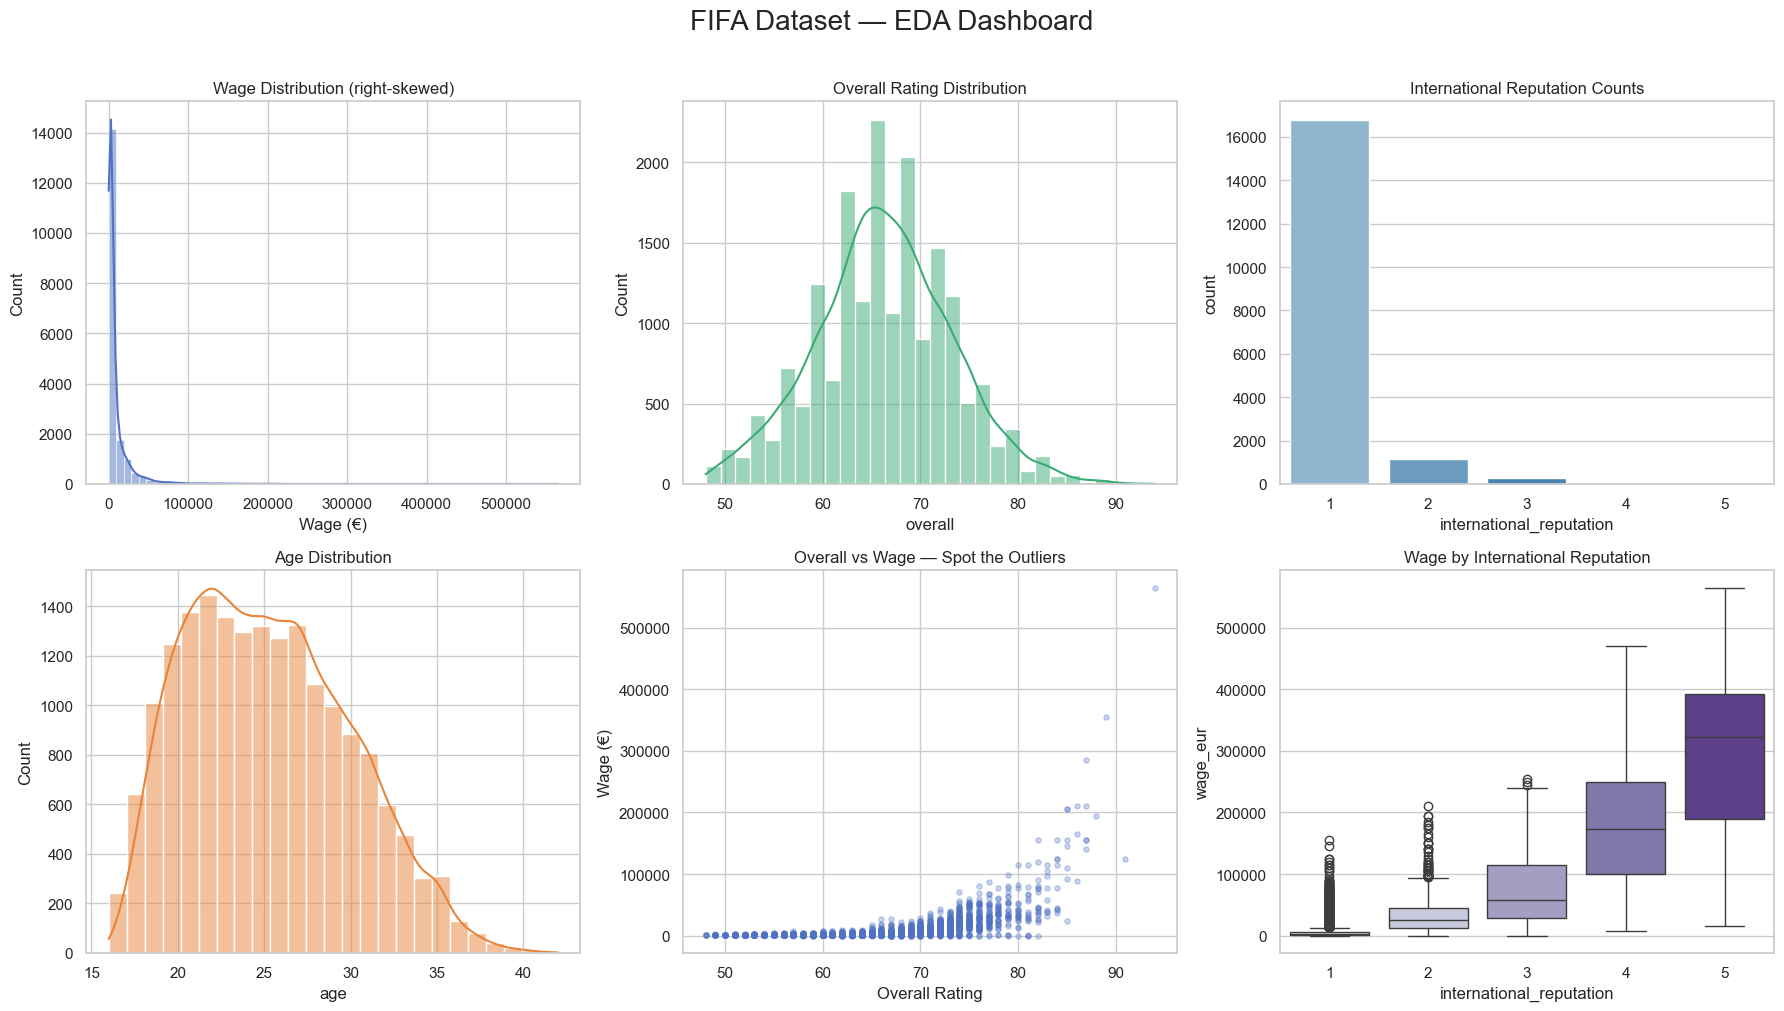

Saved: eda_dashboard.png


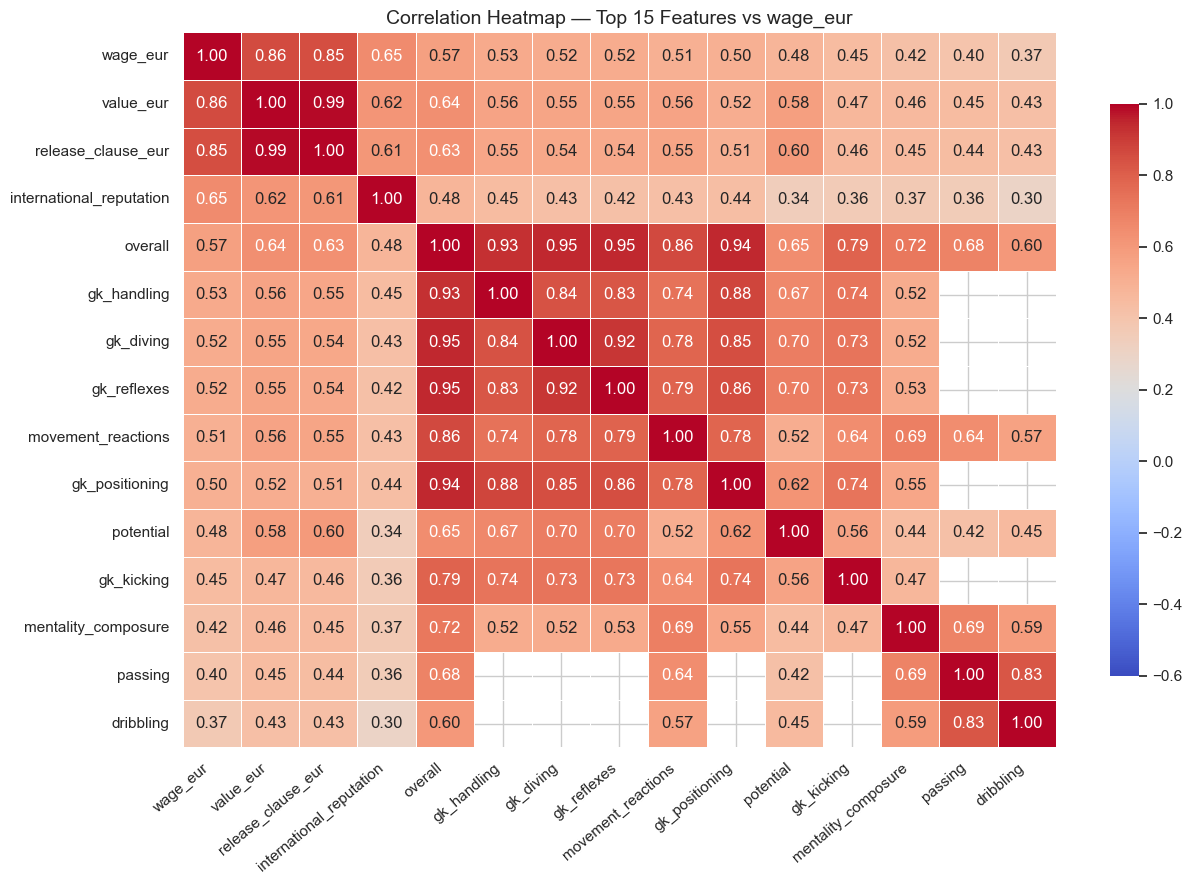

Saved: eda_heatmap.png


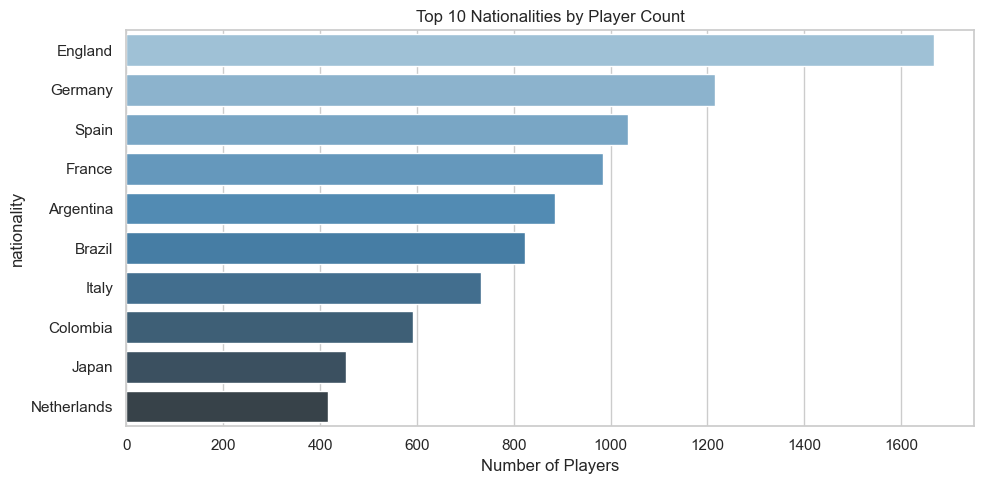

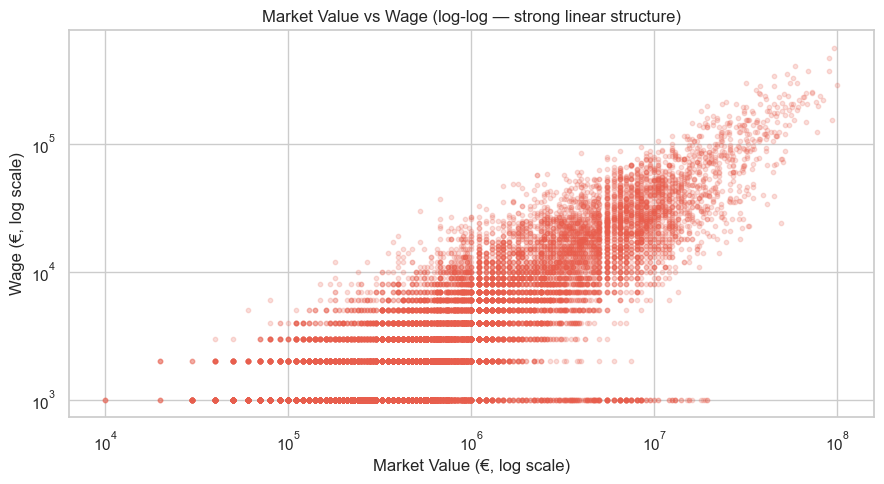


✅  Preprocessing complete.
   Shape       : (18278, 82)
   Text cols   : NONE
   Null cols   : NONE

── ANOMALY DETECTION (Isolation Forest) ──
   Anomalies detected : 183
   Sample anomalies   :
   age  overall  value_eur  wage_eur
0   32       94   95500000    565000
1   34       93   58500000    405000
2   27       92  105500000    290000
3   26       91   77500000    125000
4   28       91   90000000    470000


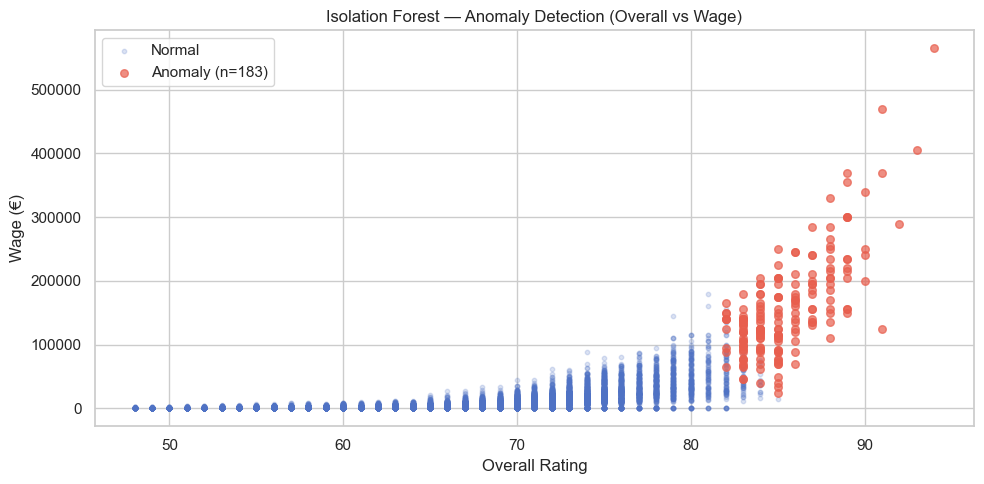


   After removal shape : (18095, 82)
Target distributions (%):

  overall_binary:
overall_binary
0    50.0
1    50.0

  overall_3class:
overall_3class
2    33.3
0    33.3
1    33.3

  rep_binary:
rep_binary
0    50.0
1    50.0



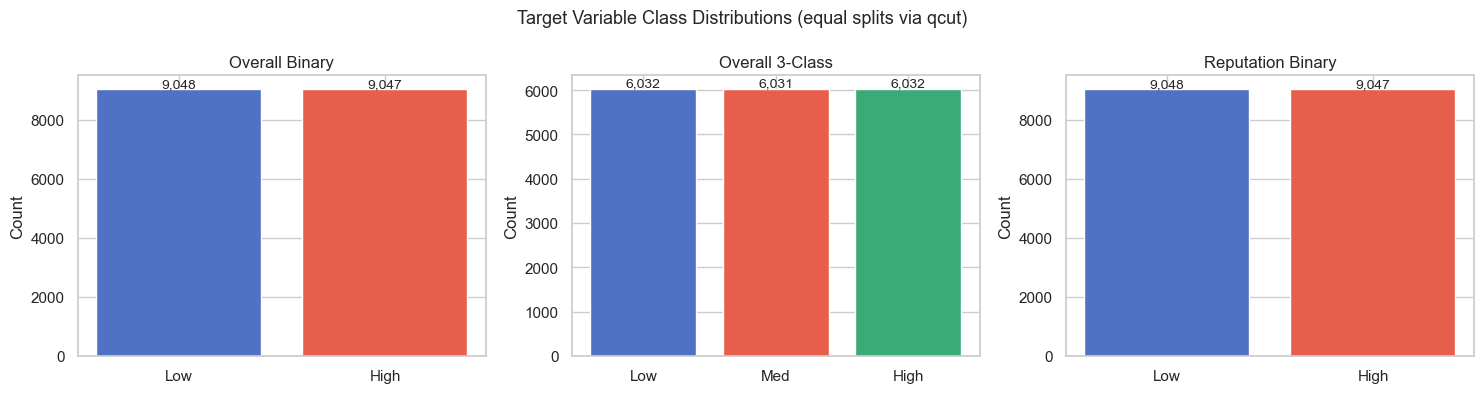


════════════════════════════════════════════════════════════
REGRESSION 1 — wage_eur
════════════════════════════════════════════════════════════

Model Performance:
  Linear Regression          R²=0.6956  MAE=€4,039  RMSE=€7,225
  Random Forest              R²=0.7619  MAE=€3,252  RMSE=€6,389


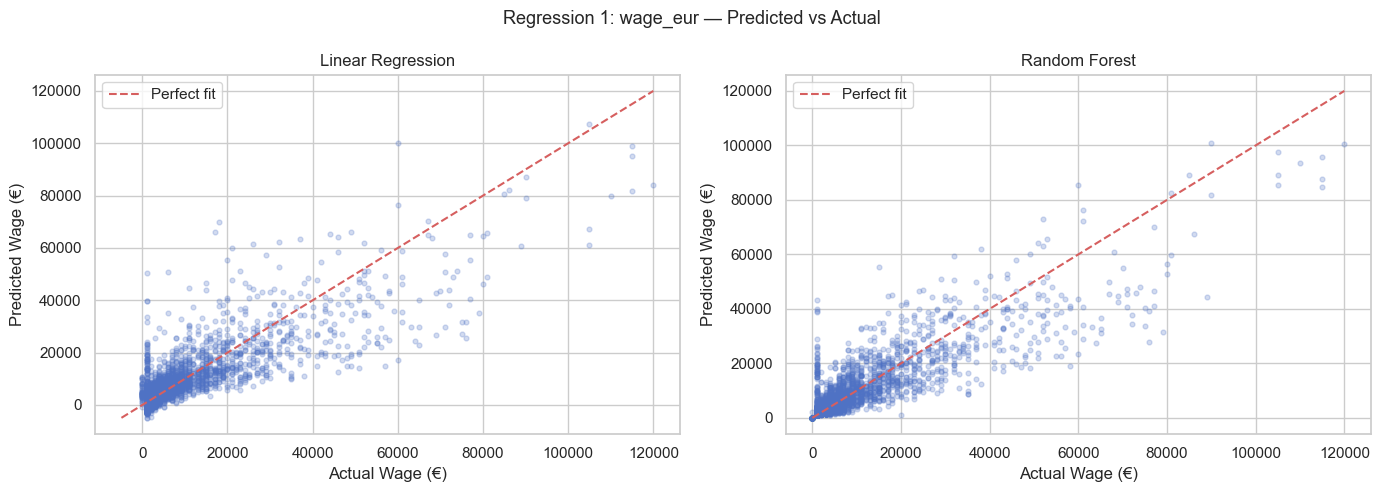

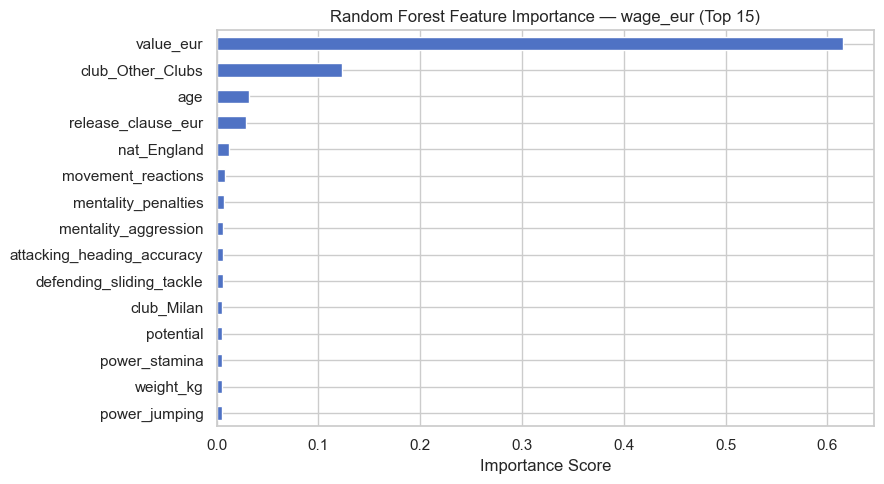


════════════════════════════════════════════════════════════
REGRESSION 2 — overall
════════════════════════════════════════════════════════════

Model Performance:
  Linear Regression          R²=0.9363  MAE=€1  RMSE=€2
  Random Forest              R²=0.9968  MAE=€0  RMSE=€0


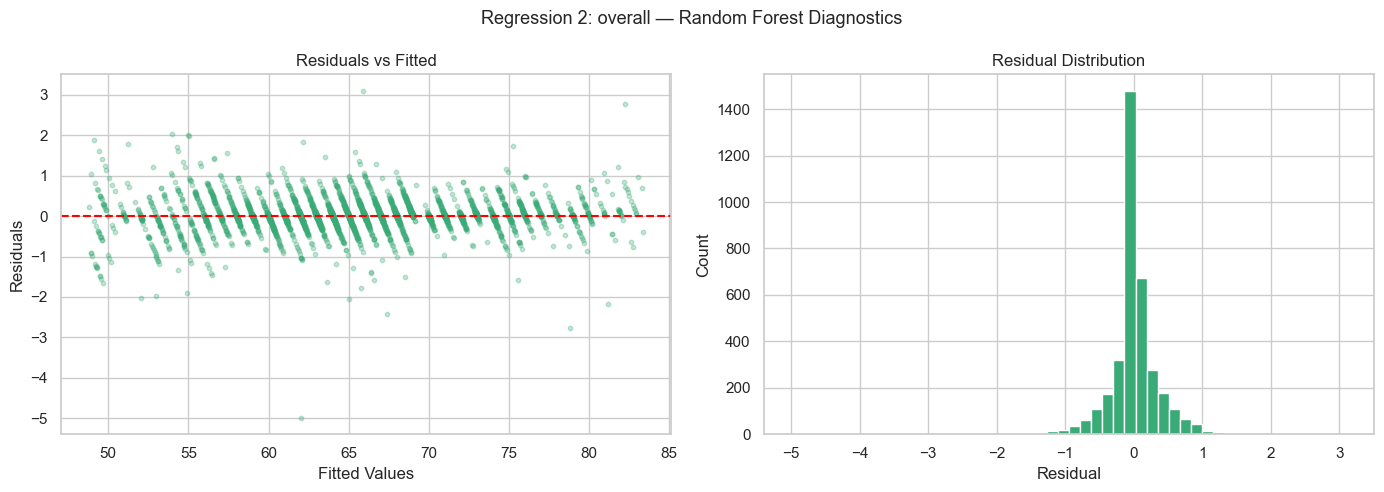


════════════════════════════════════════════════════════════
CLASSIFICATION 1 — international_reputation (binary)
════════════════════════════════════════════════════════════

  Logistic Regression  (Accuracy: 0.8229)
              precision    recall  f1-score   support

     Low Rep       0.80      0.86      0.83      1810
    High Rep       0.85      0.79      0.82      1809

    accuracy                           0.82      3619
   macro avg       0.82      0.82      0.82      3619
weighted avg       0.82      0.82      0.82      3619


  Random Forest  (Accuracy: 0.9207)
              precision    recall  f1-score   support

     Low Rep       0.88      0.98      0.92      1810
    High Rep       0.97      0.87      0.92      1809

    accuracy                           0.92      3619
   macro avg       0.93      0.92      0.92      3619
weighted avg       0.93      0.92      0.92      3619



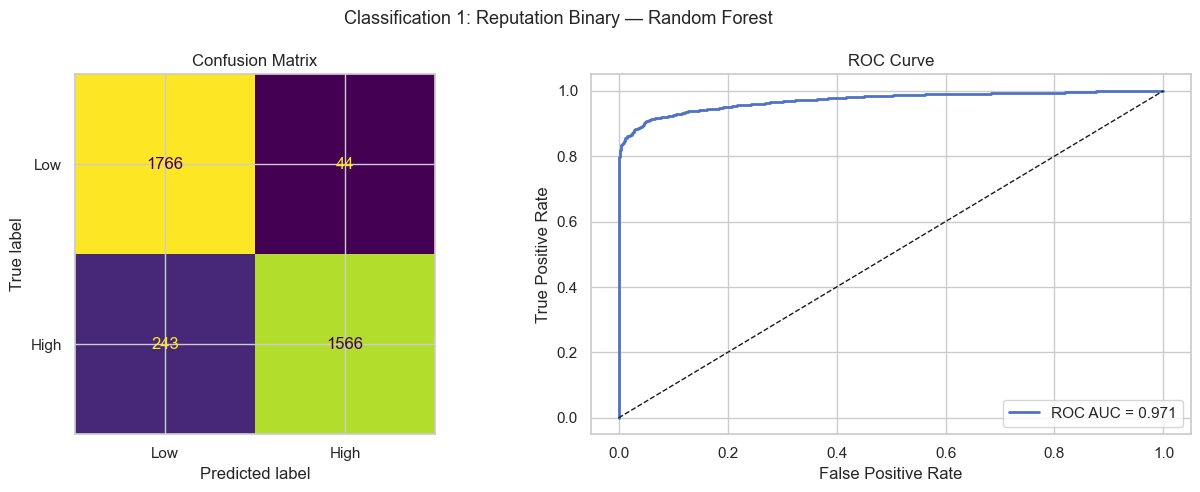


════════════════════════════════════════════════════════════
CLASSIFICATION 2 — overall_3class (Low / Med / High)
════════════════════════════════════════════════════════════

  Random Forest Report:
              precision    recall  f1-score   support

         Low       0.97      0.93      0.95      1207
      Medium       0.88      0.96      0.91      1206
        High       0.99      0.93      0.96      1206

    accuracy                           0.94      3619
   macro avg       0.94      0.94      0.94      3619
weighted avg       0.94      0.94      0.94      3619



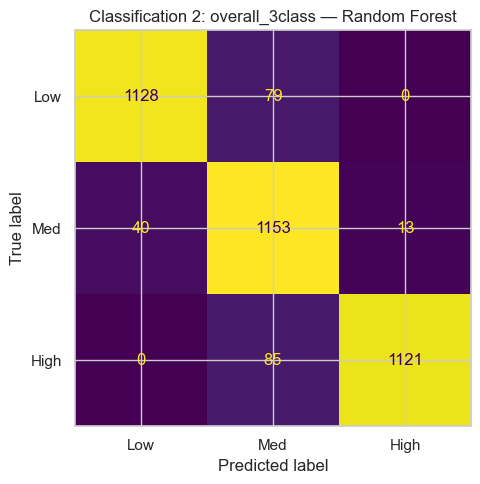


════════════════════════════════════════════════════════════
CLASSIFICATION 3 — overall_binary (Low / High)
════════════════════════════════════════════════════════════

  Random Forest Report:
              precision    recall  f1-score   support

         Low       0.97      0.97      0.97      1810
        High       0.97      0.97      0.97      1809

    accuracy                           0.97      3619
   macro avg       0.97      0.97      0.97      3619
weighted avg       0.97      0.97      0.97      3619



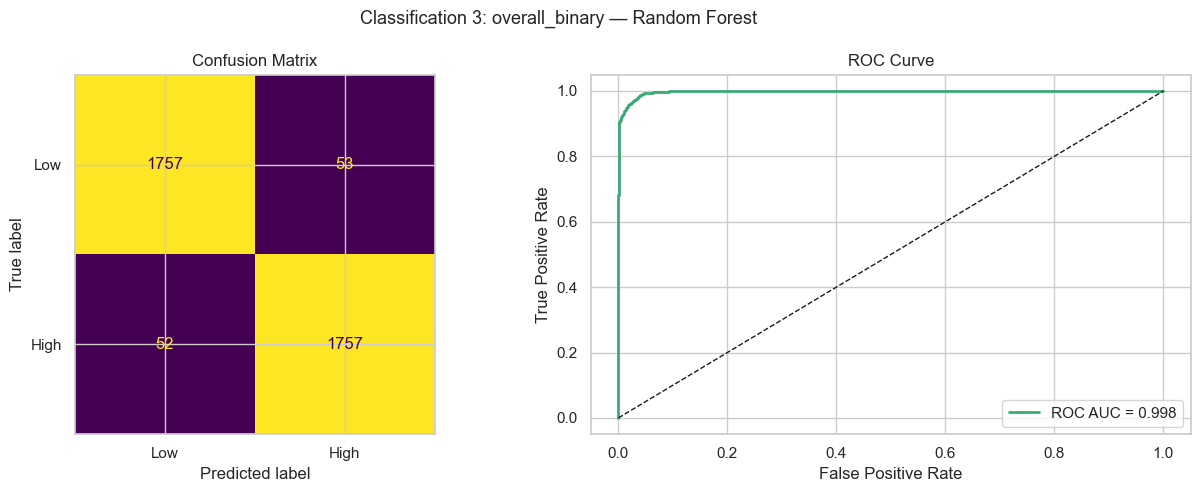

SHAP not installed — skip Cell 12. Run: pip install shap

✅  Clean dataset exported: FIFA_clean_for_PowerBI.csv
   Shape: (18095, 88)

   Key columns for Power BI:
   ['age', 'overall', 'wage_eur', 'value_eur', 'international_reputation', 'release_clause_eur', 'overall_binary_label', 'overall_3class_label', 'rep_binary_label', 'is_starter', 'is_on_loan', 'good_traits_count', 'bad_traits_count']

════════════════════════════════════════════════════════════
FINAL MODEL PERFORMANCE SUMMARY
════════════════════════════════════════════════════════════
                   Target               Metric
        wage_eur — Linear R²=0.696  MAE=4039.3
            wage_eur — RF R²=0.762  MAE=3252.2
         overall — Linear    R²=0.936  MAE=1.3
             overall — RF    R²=0.997  MAE=0.2
    rep_binary — Logistic       Accuracy=0.823
          rep_binary — RF       Accuracy=0.921
      overall_3class — RF       Accuracy=0.940
overall_binary — Logistic       Accuracy=0.953
      overall_binary — R

In [66]:
"""
╔══════════════════════════════════════════════════════════════════════════════╗
║         FIFA PLAYER ANALYSIS — COMPLETE DATA SCIENCE PROJECT                ║
║  Covers: EDA · Preprocessing · Anomaly Detection · 5 ML Targets            ║
║          SHAP Explainability · Power BI Export                              ║
╚══════════════════════════════════════════════════════════════════════════════╝

TARGETS COVERED
───────────────
1. wage_eur            → Regression
2. overall             → Regression
3. international_rep   → Binary Classification (High / Low, equal split)
4. overall_3class      → Multi-class Classification (Low / Med / High, equal split)
5. overall_binary      → Binary Classification (High / Low, equal split)

NOTEBOOK STRUCTURE
──────────────────
CELL 01 — Library Imports
CELL 02 — Data Load & Raw Audit
CELL 03 — EDA Visualizations (7 plots)
CELL 04 — Full Preprocessing Pipeline (from conversation history)
CELL 05 — Anomaly Detection (Isolation Forest — creative step)
CELL 06 — Target Variable Engineering (qcut equal splits)
CELL 07 — Regression 1: wage_eur
CELL 08 — Regression 2: overall
CELL 09 — Classification 1: international_reputation (binary)
CELL 10 — Classification 2: overall_3class (3-class)
CELL 11 — Classification 3: overall_binary (binary)
CELL 12 — SHAP Explainability (one plot per model)
CELL 13 — Export clean CSV for Power BI
"""

# ═══════════════════════════════════════════════════════════════════════════════
# CELL 01 — LIBRARY IMPORTS
# ═══════════════════════════════════════════════════════════════════════════════

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

# Scikit-learn
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.ensemble import (RandomForestRegressor, RandomForestClassifier,
                               GradientBoostingClassifier, IsolationForest)
from sklearn.metrics import (mean_absolute_error, mean_squared_error, r2_score,
                              accuracy_score, classification_report,
                              confusion_matrix, ConfusionMatrixDisplay,
                              roc_curve, auc, roc_auc_score)
from sklearn.inspection import permutation_importance

# XGBoost
try:
    from xgboost import XGBRegressor, XGBClassifier
    XGBOOST_AVAILABLE = True
except ImportError:
    XGBOOST_AVAILABLE = False
    print("XGBoost not found — install with: pip install xgboost")

# SHAP
try:
    import shap
    SHAP_AVAILABLE = True
except ImportError:
    SHAP_AVAILABLE = False
    print("SHAP not found — install with: pip install shap")

print("✅  All libraries loaded.")


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 02 — DATA LOAD & RAW AUDIT
# ═══════════════════════════════════════════════════════════════════════════════

# ── Change path if needed ──
df_raw = pd.read_excel("FIFA2020_dataset.xlsx")   # or .read_excel(...)

print(f"Raw shape : {df_raw.shape}")
print(f"\nData types summary:\n{df_raw.dtypes.value_counts()}")
print(f"\nMissing values (top 15):")
missing = df_raw.isnull().sum().sort_values(ascending=False)
print(missing[missing > 0].head(15))


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 03 — EDA VISUALIZATIONS  (run on RAW data before cleaning)
# ═══════════════════════════════════════════════════════════════════════════════

sns.set_theme(style="whitegrid", palette="muted")
PLOT_COLOR   = "#4F72C4"
ACCENT_COLOR = "#E85E4D"

# ─── 3.1  Dashboard: Distributions of key targets ───────────────────────────
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
fig.suptitle("FIFA Dataset — EDA Dashboard", fontsize=20, fontweight="500", y=1.01)

# Wage distribution
sns.histplot(df_raw["wage_eur"].dropna(), bins=60, kde=True,
             ax=axes[0, 0], color=PLOT_COLOR)
axes[0, 0].set_title("Wage Distribution (right-skewed)")
axes[0, 0].ticklabel_format(style="plain", axis="x")
axes[0, 0].set_xlabel("Wage (€)")

# Overall distribution
sns.histplot(df_raw["overall"].dropna(), bins=30, kde=True,
             ax=axes[0, 1], color="#3aaa77")
axes[0, 1].set_title("Overall Rating Distribution")

# International Reputation
sns.countplot(x="international_reputation", data=df_raw,
              ax=axes[0, 2], palette="Blues_d")
axes[0, 2].set_title("International Reputation Counts")

# Age distribution
sns.histplot(df_raw["age"].dropna(), bins=25, kde=True,
             ax=axes[1, 0], color="#e8833a")
axes[1, 0].set_title("Age Distribution")

# Overall vs Wage scatter (anomaly preview)
sample = df_raw.sample(min(3000, len(df_raw)), random_state=42)
axes[1, 1].scatter(sample["overall"], sample["wage_eur"],
                   alpha=0.3, s=14, color=PLOT_COLOR)
axes[1, 1].set_title("Overall vs Wage — Spot the Outliers")
axes[1, 1].set_xlabel("Overall Rating")
axes[1, 1].set_ylabel("Wage (€)")
axes[1, 1].ticklabel_format(style="plain", axis="y")

# Reputation × Wage boxplot
sns.boxplot(x="international_reputation", y="wage_eur",
            data=df_raw, ax=axes[1, 2], palette="Purples")
axes[1, 2].set_title("Wage by International Reputation")
axes[1, 2].ticklabel_format(style="plain", axis="y")

plt.tight_layout()
plt.savefig("eda_dashboard.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: eda_dashboard.png")


# ─── 3.2  Correlation Heatmap — top 15 features vs wage_eur ─────────────────
numeric_df = df_raw.select_dtypes(include=[np.number])
top15 = (numeric_df.corr()["wage_eur"]
         .abs()
         .sort_values(ascending=False)
         .head(15)
         .index)

plt.figure(figsize=(13, 9))
sns.heatmap(numeric_df[top15].corr(),
            annot=True, fmt=".2f", cmap="coolwarm",
            linewidths=0.4, vmax=1, vmin=-0.6,
            cbar_kws={"shrink": 0.8})
plt.title("Correlation Heatmap — Top 15 Features vs wage_eur", fontsize=14)
plt.xticks(rotation=40, ha="right")
plt.tight_layout()
plt.savefig("eda_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: eda_heatmap.png")


# ─── 3.3  Top 10 Nationalities by player count ──────────────────────────────
top_nat = df_raw["nationality"].value_counts().head(10)
plt.figure(figsize=(10, 5))
sns.barplot(x=top_nat.values, y=top_nat.index, palette="Blues_d")
plt.title("Top 10 Nationalities by Player Count")
plt.xlabel("Number of Players")
plt.tight_layout()
plt.savefig("eda_nationalities.png", dpi=150, bbox_inches="tight")
plt.show()


# ─── 3.4  Value vs Wage — log scale reveals structure ───────────────────────
plt.figure(figsize=(9, 5))
plt.scatter(df_raw["value_eur"].clip(upper=1e8),
            df_raw["wage_eur"].clip(upper=6e5),
            alpha=0.2, s=10, color=ACCENT_COLOR)
plt.xscale("log")
plt.yscale("log")
plt.xlabel("Market Value (€, log scale)")
plt.ylabel("Wage (€, log scale)")
plt.title("Market Value vs Wage (log-log — strong linear structure)")
plt.tight_layout()
plt.savefig("eda_value_vs_wage.png", dpi=150, bbox_inches="tight")
plt.show()


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 04 — FULL PREPROCESSING PIPELINE
# ═══════════════════════════════════════════════════════════════════════════════

df = df_raw.copy()

# ── 4.1  Drop identity / junk columns ────────────────────────────────────────
drop_identity = [
    "sofifa_id", "player_url", "short_name", "long_name",
    "dob", "real_face", "team_jersey_number",
    "player_tags", "nation_position", "nation_jersey_number",
    "joined",
]
df.drop(columns=drop_identity, errors="ignore", inplace=True)

# ── 4.2  Drop "89+2" position-rating columns ─────────────────────────────────
pos_rating_cols = [
    "ls", "st", "rs", "lw", "lf", "cf", "rf", "rw",
    "lam", "cam", "ram", "lm", "lcm", "cm", "rcm", "rm",
    "lwb", "ldm", "cdm", "rdm", "rwb", "lb", "lcb", "cb", "rcb", "rb",
]
df.drop(columns=pos_rating_cols, errors="ignore", inplace=True)

# ── 4.3  Drop high-NaN summary float stats ───────────────────────────────────
summary_floats = [
    "pace", "shooting", "passing", "dribbling", "defending", "physic",
    "gk_diving", "gk_handling", "gk_kicking",
    "gk_reflexes", "gk_speed", "gk_positioning",
]
df.drop(columns=summary_floats, errors="ignore", inplace=True)

# ── 4.4  Fill granular skill NaNs with 0 ─────────────────────────────────────
granular_skills = [
    "attacking_crossing", "attacking_finishing", "attacking_heading_accuracy",
    "attacking_short_passing", "attacking_volleys",
    "skill_dribbling", "skill_curve", "skill_fk_accuracy",
    "skill_long_passing", "skill_ball_control",
    "movement_acceleration", "movement_sprint_speed", "movement_agility",
    "movement_reactions", "movement_balance",
    "power_shot_power", "power_jumping", "power_stamina",
    "power_strength", "power_long_shots",
    "mentality_aggression", "mentality_interceptions",
    "mentality_positioning", "mentality_vision",
    "mentality_penalties", "mentality_composure",
    "defending_marking", "defending_standing_tackle", "defending_sliding_tackle",
    "goalkeeping_diving", "goalkeeping_handling", "goalkeeping_kicking",
    "goalkeeping_positioning", "goalkeeping_reflexes",
]
existing_skills = [c for c in granular_skills if c in df.columns]
df[existing_skills] = df[existing_skills].fillna(0)

# ── 4.5  release_clause_eur — fill with median ───────────────────────────────
if "release_clause_eur" in df.columns:
    med = df["release_clause_eur"].median()
    df["release_clause_eur"] = df["release_clause_eur"].fillna(med).astype(float)

# ── 4.6  contract_valid_until → years_until_expiration ───────────────────────
CURRENT_YEAR = 2026
if "contract_valid_until" in df.columns:
    df["contract_valid_until"] = pd.to_numeric(df["contract_valid_until"], errors="coerce")
    df["years_until_expiration"] = (
        (df["contract_valid_until"] - CURRENT_YEAR).clip(lower=0).fillna(0).astype(int)
    )
    df.drop(columns=["contract_valid_until"], inplace=True)

# ── 4.7  body_type → ordinal 1-3 ─────────────────────────────────────────────
if "body_type" in df.columns:
    body_map = {
        "Lean": 1, "Neymar": 1, "Messi": 1,
        "Normal": 2, "Courtois": 2, "Shaqiri": 2, "PLAYER_BODY_TYPE_25": 2,
        "Stocky": 3, "C. Ronaldo": 3, "Akinfenwa": 3,
    }
    df["body_type_num"] = df["body_type"].map(body_map).fillna(2).astype(int)
    df.drop(columns=["body_type"], inplace=True)

# ── 4.8  preferred_foot — drop (bias risk in Linear Regression) ──────────────
df.drop(columns=["preferred_foot"], errors="ignore", inplace=True)

# ── 4.9  work_rate → split + ordinal ─────────────────────────────────────────
if "work_rate" in df.columns:
    rate_map = {"High": 3, "Medium": 2, "Low": 1}
    split_wr = df["work_rate"].str.split("/", expand=True)
    df["work_rate_att"] = split_wr[0].str.strip().map(rate_map).fillna(2).astype(int)
    df["work_rate_def"] = split_wr[1].str.strip().map(rate_map).fillna(2).astype(int)
    df.drop(columns=["work_rate"], inplace=True)

# ── 4.10 player_traits → good / bad counts ───────────────────────────────────
BAD_TRAITS = {
    "Argues with Officials", "Selfish", "Diver",
    "Injury Prone", "Inflexible", "Dives Into Tackles",
}

def count_traits(text):
    if pd.isna(text) or text == "":
        return 0, 0
    items = [t.strip() for t in text.split(",")]
    bad  = sum(1 for t in items if t in BAD_TRAITS)
    return len(items) - bad, bad

if "player_traits" in df.columns:
    df[["good_traits_count", "bad_traits_count"]] = (
        df["player_traits"].apply(lambda x: pd.Series(count_traits(x)))
    )
    df.drop(columns=["player_traits"], inplace=True)

# ── 4.11 nationality — Top-10 + Other → one-hot ──────────────────────────────
if "nationality" in df.columns:
    top10_nat = df["nationality"].value_counts().nlargest(10).index.tolist()
    df["nat_grp"] = df["nationality"].apply(
        lambda x: x if x in top10_nat else "Other"
    )
    df = pd.get_dummies(df, columns=["nat_grp"], prefix="nat", dtype=int)
    df.drop(columns=["nationality"], errors="ignore", inplace=True)

# ── 4.12 club — Elite-15 + Other → one-hot ───────────────────────────────────
if "club" in df.columns:
    ELITE_15 = [
        "Real Madrid", "FC Barcelona", "Manchester United", "Liverpool",
        "Manchester City", "FC Bayern München", "Paris Saint-Germain",
        "Arsenal", "Tottenham Hotspur", "Chelsea",
        "Inter", "Borussia Dortmund", "Atlético Madrid",
        "Milan", "Juventus",
    ]
    df["club_cat"] = df["club"].apply(
        lambda x: x if x in ELITE_15 else "Other_Clubs"
    )
    df = pd.get_dummies(df, columns=["club_cat"], prefix="club", dtype=int)
    df.drop(columns=["club"], errors="ignore", inplace=True)

# ── 4.13 player_positions → tactical role → one-hot ──────────────────────────
if "player_positions" in df.columns:
    POS_MAP = {
        "ST": "Attack", "LS": "Attack", "RS": "Attack",
        "CF": "Attack", "RF": "Attack", "LF": "Attack",
        "RW": "Attack", "LW": "Attack",
        "CAM": "Mid", "RAM": "Mid", "LAM": "Mid",
        "RM":  "Mid", "LM":  "Mid",
        "CM":  "Mid", "RCM": "Mid", "LCM": "Mid",
        "CDM": "Mid", "RDM": "Mid", "LDM": "Mid",
        "CB":  "Def", "RCB": "Def", "LCB": "Def",
        "RB":  "Def", "LB":  "Def",
        "RWB": "Def", "LWB": "Def",
        "GK":  "GK",
    }
    df["primary_pos"] = df["player_positions"].str.split(",").str[0].str.strip()
    df["role"] = df["primary_pos"].map(POS_MAP).fillna("Mid")
    df = pd.get_dummies(df, columns=["role"], prefix="role", dtype=int)
    df.drop(columns=["player_positions", "primary_pos"], errors="ignore", inplace=True)

# ── 4.14 team_position → is_starter (binary) ─────────────────────────────────
if "team_position" in df.columns:
    df["is_starter"] = df["team_position"].apply(
        lambda x: 0 if (pd.isna(x) or x in ["SUB", "RES"]) else 1
    ).astype(int)
    df.drop(columns=["team_position"], inplace=True)

# ── 4.15 loaned_from → is_on_loan (binary) ───────────────────────────────────
if "loaned_from" in df.columns:
    df["is_on_loan"] = df["loaned_from"].notnull().astype(int)
    df.drop(columns=["loaned_from"], inplace=True)

# ── 4.16 Drop any remaining text columns ─────────────────────────────────────
leftover = df.select_dtypes(include="object").columns.tolist()
if leftover:
    df.drop(columns=leftover, inplace=True)
    print(f"Dropped residual text: {leftover}")

# ── 4.17 Drop rows where either key target is null ───────────────────────────
df.dropna(subset=["wage_eur", "overall", "international_reputation"], inplace=True)
df.reset_index(drop=True, inplace=True)

print(f"\n✅  Preprocessing complete.")
print(f"   Shape       : {df.shape}")
print(f"   Text cols   : {df.select_dtypes('object').columns.tolist() or 'NONE'}")
print(f"   Null cols   : {df.columns[df.isnull().any()].tolist() or 'NONE'}")


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 05 — ANOMALY DETECTION (Isolation Forest — Creative Step)
# ═══════════════════════════════════════════════════════════════════════════════

print("\n── ANOMALY DETECTION (Isolation Forest) ──")

iso_features = ["age", "overall", "potential", "value_eur", "wage_eur"]
iso_data = df[iso_features].copy()

iso_forest = IsolationForest(
    contamination=0.01,   # Flag the weirdest 1 %
    n_estimators=200,
    random_state=42,
    n_jobs=-1,
)
df["anomaly_score"] = iso_forest.fit_predict(iso_data)

n_anomalies = (df["anomaly_score"] == -1).sum()
print(f"   Anomalies detected : {n_anomalies}")
print(f"   Sample anomalies   :")
print(df[df["anomaly_score"] == -1][["age", "overall", "value_eur", "wage_eur"]].head(5))

# ─── Visualize anomalies on the scatter ──────────────────────────────────────
fig, ax = plt.subplots(figsize=(10, 5))
normal   = df[df["anomaly_score"] ==  1]
outliers = df[df["anomaly_score"] == -1]
ax.scatter(normal["overall"],   normal["wage_eur"],   alpha=0.2, s=10,
           color=PLOT_COLOR, label="Normal")
ax.scatter(outliers["overall"], outliers["wage_eur"], alpha=0.7, s=30,
           color=ACCENT_COLOR, label=f"Anomaly (n={n_anomalies})", zorder=5)
ax.set_title("Isolation Forest — Anomaly Detection (Overall vs Wage)")
ax.set_xlabel("Overall Rating")
ax.set_ylabel("Wage (€)")
ax.ticklabel_format(style="plain", axis="y")
ax.legend()
plt.tight_layout()
plt.savefig("anomaly_detection.png", dpi=150, bbox_inches="tight")
plt.show()

# Remove anomalies and clean up
df = df[df["anomaly_score"] == 1].drop(columns=["anomaly_score"]).copy()
df.reset_index(drop=True, inplace=True)
print(f"\n   After removal shape : {df.shape}")


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 06 — TARGET VARIABLE ENGINEERING (equal-size splits with qcut)
# ═══════════════════════════════════════════════════════════════════════════════

# ── Regression targets (keep numeric) ────────────────────────────────────────
# wage_eur and overall already exist

# ── Binary: overall → 2 equal classes ───────────────────────────────────────
df["overall_binary"] = pd.qcut(
    df["overall"].rank(method="first"), q=2, labels=[0, 1]  # 0=Low, 1=High
).astype(int)

# ── 3-class: overall → 3 equal classes ──────────────────────────────────────
df["overall_3class"] = pd.qcut(
    df["overall"].rank(method="first"), q=3, labels=[0, 1, 2]  # 0=Low,1=Med,2=High
).astype(int)

# ── Binary: international_reputation → 2 equal classes ──────────────────────
df["rep_binary"] = pd.qcut(
    df["international_reputation"].rank(method="first"), q=2, labels=[0, 1]
).astype(int)

print("Target distributions (%):\n")
for col in ["overall_binary", "overall_3class", "rep_binary"]:
    print(f"  {col}:")
    print((df[col].value_counts(normalize=True) * 100).round(1).to_string())
    print()


# ─── Visualize target distributions ─────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle("Target Variable Class Distributions (equal splits via qcut)", fontsize=13)

for ax, col, title, labels in zip(
    axes,
    ["overall_binary", "overall_3class", "rep_binary"],
    ["Overall Binary", "Overall 3-Class", "Reputation Binary"],
    [["Low", "High"], ["Low", "Med", "High"], ["Low", "High"]],
):
    counts = df[col].value_counts().sort_index()
    ax.bar(labels, counts.values, color=["#4F72C4", "#E85E4D", "#3aaa77"][:len(labels)])
    ax.set_title(title)
    ax.set_ylabel("Count")
    for i, v in enumerate(counts.values):
        ax.text(i, v + 50, f"{v:,}", ha="center", fontsize=10)

plt.tight_layout()
plt.savefig("target_distributions.png", dpi=150, bbox_inches="tight")
plt.show()


# ═══════════════════════════════════════════════════════════════════════════════
# HELPER: build feature matrix (exclude all target columns)
# ═══════════════════════════════════════════════════════════════════════════════

TARGET_COLS = ["wage_eur", "overall", "international_reputation",
               "overall_binary", "overall_3class", "rep_binary"]

def get_X(df, target):
    """Return feature matrix excluding all target columns."""
    drop_cols = [c for c in TARGET_COLS if c in df.columns]
    return df.drop(columns=drop_cols)

def scale_split(X, y, test_size=0.2, random_state=42, stratify=None):
    """Train/test split + StandardScaler. Returns train/test splits + scaler."""
    X_tr, X_te, y_tr, y_te = train_test_split(
        X, y, test_size=test_size, random_state=random_state, stratify=stratify
    )
    scaler = StandardScaler()
    X_tr_s = scaler.fit_transform(X_tr)
    X_te_s  = scaler.transform(X_te)
    return X_tr_s, X_te_s, y_tr, y_te, scaler, X_tr.columns.tolist()


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 07 — REGRESSION 1: wage_eur
# ═══════════════════════════════════════════════════════════════════════════════

print("\n" + "═" * 60)
print("REGRESSION 1 — wage_eur")
print("═" * 60)

X_w = get_X(df, "wage_eur")
y_w = df["wage_eur"]

X_w_tr, X_w_te, y_w_tr, y_w_te, scaler_w, feat_names_w = scale_split(X_w, y_w)

# ─── Linear Regression ───────────────────────────────────────────────────────
lr_w = LinearRegression()
lr_w.fit(X_w_tr, y_w_tr)
lr_w_pred = lr_w.predict(X_w_te)

# ─── Random Forest Regressor ─────────────────────────────────────────────────
rf_w = RandomForestRegressor(n_estimators=200, max_depth=12,
                              random_state=42, n_jobs=-1)
rf_w.fit(X_w_tr, y_w_tr)
rf_w_pred = rf_w.predict(X_w_te)

# ─── XGBoost Regressor ───────────────────────────────────────────────────────
if XGBOOST_AVAILABLE:
    xgb_w = XGBRegressor(n_estimators=300, learning_rate=0.05,
                          max_depth=6, random_state=42,
                          verbosity=0, n_jobs=-1)
    xgb_w.fit(X_w_tr, y_w_tr)
    xgb_w_pred = xgb_w.predict(X_w_te)

# ─── Results ─────────────────────────────────────────────────────────────────
def reg_report(name, y_true, y_pred):
    r2  = r2_score(y_true, y_pred)
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    print(f"  {name:<25}  R²={r2:.4f}  MAE=€{mae:,.0f}  RMSE=€{rmse:,.0f}")
    return r2, mae, rmse

print("\nModel Performance:")
reg_report("Linear Regression",    y_w_te, lr_w_pred)
reg_report("Random Forest",        y_w_te, rf_w_pred)
if XGBOOST_AVAILABLE:
    reg_report("XGBoost",          y_w_te, xgb_w_pred)

# ─── Predicted vs Actual plot ─────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Regression 1: wage_eur — Predicted vs Actual", fontsize=13)

best_pred = xgb_w_pred if XGBOOST_AVAILABLE else rf_w_pred
best_name = "XGBoost" if XGBOOST_AVAILABLE else "Random Forest"

for ax, preds, name in zip(
    axes,
    [lr_w_pred, best_pred],
    ["Linear Regression", best_name],
):
    ax.scatter(y_w_te, preds, alpha=0.25, s=12, color=PLOT_COLOR)
    mn, mx = min(y_w_te.min(), preds.min()), max(y_w_te.max(), preds.max())
    ax.plot([mn, mx], [mn, mx], "r--", lw=1.5, label="Perfect fit")
    ax.set_title(name)
    ax.set_xlabel("Actual Wage (€)")
    ax.set_ylabel("Predicted Wage (€)")
    ax.ticklabel_format(style="plain", axis="both")
    ax.legend()

plt.tight_layout()
plt.savefig("reg1_wage_pred_vs_actual.png", dpi=150, bbox_inches="tight")
plt.show()

# ─── Feature importance (Random Forest) ──────────────────────────────────────
fi_w = pd.Series(rf_w.feature_importances_, index=feat_names_w).nlargest(15)
plt.figure(figsize=(9, 5))
fi_w.sort_values().plot(kind="barh", color=PLOT_COLOR)
plt.title("Random Forest Feature Importance — wage_eur (Top 15)")
plt.xlabel("Importance Score")
plt.tight_layout()
plt.savefig("reg1_feature_importance.png", dpi=150, bbox_inches="tight")
plt.show()


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 08 — REGRESSION 2: overall
# ═══════════════════════════════════════════════════════════════════════════════

print("\n" + "═" * 60)
print("REGRESSION 2 — overall")
print("═" * 60)

X_o = get_X(df, "overall")
y_o = df["overall"]

X_o_tr, X_o_te, y_o_tr, y_o_te, scaler_o, feat_names_o = scale_split(X_o, y_o)

lr_o = LinearRegression()
lr_o.fit(X_o_tr, y_o_tr)
lr_o_pred = lr_o.predict(X_o_te)

rf_o = RandomForestRegressor(n_estimators=200, max_depth=12,
                              random_state=42, n_jobs=-1)
rf_o.fit(X_o_tr, y_o_tr)
rf_o_pred = rf_o.predict(X_o_te)

if XGBOOST_AVAILABLE:
    xgb_o = XGBRegressor(n_estimators=300, learning_rate=0.05,
                          max_depth=6, random_state=42, verbosity=0, n_jobs=-1)
    xgb_o.fit(X_o_tr, y_o_tr)
    xgb_o_pred = xgb_o.predict(X_o_te)

print("\nModel Performance:")
reg_report("Linear Regression",  y_o_te, lr_o_pred)
reg_report("Random Forest",      y_o_te, rf_o_pred)
if XGBOOST_AVAILABLE:
    reg_report("XGBoost",        y_o_te, xgb_o_pred)

# ─── Residual plot ────────────────────────────────────────────────────────────
best_o_pred = xgb_o_pred if XGBOOST_AVAILABLE else rf_o_pred
best_o_name = "XGBoost" if XGBOOST_AVAILABLE else "Random Forest"
residuals   = y_o_te - best_o_pred

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle(f"Regression 2: overall — {best_o_name} Diagnostics", fontsize=13)

axes[0].scatter(best_o_pred, residuals, alpha=0.3, s=10, color="#3aaa77")
axes[0].axhline(0, color="red", lw=1.5, ls="--")
axes[0].set_title("Residuals vs Fitted")
axes[0].set_xlabel("Fitted Values")
axes[0].set_ylabel("Residuals")

axes[1].hist(residuals, bins=50, color="#3aaa77", edgecolor="white")
axes[1].set_title("Residual Distribution")
axes[1].set_xlabel("Residual")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.savefig("reg2_overall_diagnostics.png", dpi=150, bbox_inches="tight")
plt.show()


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 09 — CLASSIFICATION 1: international_reputation (Binary)
# ═══════════════════════════════════════════════════════════════════════════════

print("\n" + "═" * 60)
print("CLASSIFICATION 1 — international_reputation (binary)")
print("═" * 60)

X_r = get_X(df, "rep_binary")
y_r = df["rep_binary"]

X_r_tr, X_r_te, y_r_tr, y_r_te, scaler_r, feat_names_r = scale_split(
    X_r, y_r, stratify=y_r
)

# ─── Logistic Regression ─────────────────────────────────────────────────────
log_r = LogisticRegression(max_iter=1000, random_state=42)
log_r.fit(X_r_tr, y_r_tr)
log_r_pred = log_r.predict(X_r_te)
log_r_prob = log_r.predict_proba(X_r_te)[:, 1]

# ─── Random Forest ───────────────────────────────────────────────────────────
rf_r = RandomForestClassifier(n_estimators=200, max_depth=10,
                               random_state=42, n_jobs=-1)
rf_r.fit(X_r_tr, y_r_tr)
rf_r_pred = rf_r.predict(X_r_te)
rf_r_prob = rf_r.predict_proba(X_r_te)[:, 1]

# ─── XGBoost ─────────────────────────────────────────────────────────────────
if XGBOOST_AVAILABLE:
    xgb_r = XGBClassifier(n_estimators=300, learning_rate=0.05,
                           max_depth=6, random_state=42,
                           use_label_encoder=False, eval_metric="logloss",
                           verbosity=0, n_jobs=-1)
    xgb_r.fit(X_r_tr, y_r_tr)
    xgb_r_pred = xgb_r.predict(X_r_te)
    xgb_r_prob = xgb_r.predict_proba(X_r_te)[:, 1]

def clf_report(name, y_true, y_pred):
    acc = accuracy_score(y_true, y_pred)
    print(f"\n  {name}  (Accuracy: {acc:.4f})")
    print(classification_report(y_true, y_pred,
                                 target_names=["Low Rep", "High Rep"],
                                 zero_division=0))

clf_report("Logistic Regression", y_r_te, log_r_pred)
clf_report("Random Forest",       y_r_te, rf_r_pred)
if XGBOOST_AVAILABLE:
    clf_report("XGBoost",         y_r_te, xgb_r_pred)

# ─── Confusion Matrix + ROC ──────────────────────────────────────────────────
best_r_pred = xgb_r_pred if XGBOOST_AVAILABLE else rf_r_pred
best_r_prob = xgb_r_prob if XGBOOST_AVAILABLE else rf_r_prob
best_r_name = "XGBoost" if XGBOOST_AVAILABLE else "Random Forest"

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle(f"Classification 1: Reputation Binary — {best_r_name}", fontsize=13)

ConfusionMatrixDisplay(confusion_matrix(y_r_te, best_r_pred),
                       display_labels=["Low", "High"]).plot(ax=axes[0], colorbar=False)
axes[0].set_title("Confusion Matrix")

fpr, tpr, _ = roc_curve(y_r_te, best_r_prob)
roc_auc_val = auc(fpr, tpr)
axes[1].plot(fpr, tpr, color=PLOT_COLOR, lw=2,
             label=f"ROC AUC = {roc_auc_val:.3f}")
axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set_title("ROC Curve")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend()

plt.tight_layout()
plt.savefig("clf1_reputation_binary.png", dpi=150, bbox_inches="tight")
plt.show()


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 10 — CLASSIFICATION 2: overall_3class (Low / Med / High)
# ═══════════════════════════════════════════════════════════════════════════════

print("\n" + "═" * 60)
print("CLASSIFICATION 2 — overall_3class (Low / Med / High)")
print("═" * 60)

X_3 = get_X(df, "overall_3class")
y_3 = df["overall_3class"]

X_3_tr, X_3_te, y_3_tr, y_3_te, scaler_3, feat_names_3 = scale_split(
    X_3, y_3, stratify=y_3
)

rf_3 = RandomForestClassifier(n_estimators=200, max_depth=10,
                               random_state=42, n_jobs=-1)
rf_3.fit(X_3_tr, y_3_tr)
rf_3_pred = rf_3.predict(X_3_te)

if XGBOOST_AVAILABLE:
    xgb_3 = XGBClassifier(n_estimators=300, learning_rate=0.05,
                           max_depth=6, random_state=42,
                           use_label_encoder=False,
                           objective="multi:softprob",
                           num_class=3,
                           eval_metric="mlogloss", verbosity=0, n_jobs=-1)
    xgb_3.fit(X_3_tr, y_3_tr)
    xgb_3_pred = xgb_3.predict(X_3_te)

best_3_pred = xgb_3_pred if XGBOOST_AVAILABLE else rf_3_pred
best_3_name = "XGBoost" if XGBOOST_AVAILABLE else "Random Forest"

print(f"\n  {best_3_name} Report:")
print(classification_report(y_3_te, best_3_pred,
                             target_names=["Low", "Medium", "High"],
                             zero_division=0))

# ─── Confusion Matrix ─────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 5))
ConfusionMatrixDisplay(confusion_matrix(y_3_te, best_3_pred),
                       display_labels=["Low", "Med", "High"]).plot(ax=ax, colorbar=False)
ax.set_title(f"Classification 2: overall_3class — {best_3_name}")
plt.tight_layout()
plt.savefig("clf2_overall_3class.png", dpi=150, bbox_inches="tight")
plt.show()


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 11 — CLASSIFICATION 3: overall_binary (Low / High)
# ═══════════════════════════════════════════════════════════════════════════════

print("\n" + "═" * 60)
print("CLASSIFICATION 3 — overall_binary (Low / High)")
print("═" * 60)

X_ob = get_X(df, "overall_binary")
y_ob = df["overall_binary"]

X_ob_tr, X_ob_te, y_ob_tr, y_ob_te, scaler_ob, feat_names_ob = scale_split(
    X_ob, y_ob, stratify=y_ob
)

log_ob = LogisticRegression(max_iter=1000, random_state=42)
log_ob.fit(X_ob_tr, y_ob_tr)
log_ob_pred = log_ob.predict(X_ob_te)
log_ob_prob = log_ob.predict_proba(X_ob_te)[:, 1]

rf_ob = RandomForestClassifier(n_estimators=200, max_depth=10,
                                random_state=42, n_jobs=-1)
rf_ob.fit(X_ob_tr, y_ob_tr)
rf_ob_pred = rf_ob.predict(X_ob_te)
rf_ob_prob = rf_ob.predict_proba(X_ob_te)[:, 1]

if XGBOOST_AVAILABLE:
    xgb_ob = XGBClassifier(n_estimators=300, learning_rate=0.05,
                            max_depth=6, random_state=42,
                            use_label_encoder=False, eval_metric="logloss",
                            verbosity=0, n_jobs=-1)
    xgb_ob.fit(X_ob_tr, y_ob_tr)
    xgb_ob_pred = xgb_ob.predict(X_ob_te)
    xgb_ob_prob = xgb_ob.predict_proba(X_ob_te)[:, 1]

best_ob_pred = xgb_ob_pred if XGBOOST_AVAILABLE else rf_ob_pred
best_ob_prob = xgb_ob_prob if XGBOOST_AVAILABLE else rf_ob_prob
best_ob_name = "XGBoost" if XGBOOST_AVAILABLE else "Random Forest"

print(f"\n  {best_ob_name} Report:")
print(classification_report(y_ob_te, best_ob_pred,
                             target_names=["Low", "High"], zero_division=0))

# ─── Confusion Matrix + ROC ──────────────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
fig.suptitle(f"Classification 3: overall_binary — {best_ob_name}", fontsize=13)

ConfusionMatrixDisplay(confusion_matrix(y_ob_te, best_ob_pred),
                       display_labels=["Low", "High"]).plot(ax=axes[0], colorbar=False)
axes[0].set_title("Confusion Matrix")

fpr2, tpr2, _ = roc_curve(y_ob_te, best_ob_prob)
auc2 = auc(fpr2, tpr2)
axes[1].plot(fpr2, tpr2, color="#3aaa77", lw=2, label=f"ROC AUC = {auc2:.3f}")
axes[1].plot([0, 1], [0, 1], "k--", lw=1)
axes[1].set_title("ROC Curve")
axes[1].set_xlabel("False Positive Rate")
axes[1].set_ylabel("True Positive Rate")
axes[1].legend()

plt.tight_layout()
plt.savefig("clf3_overall_binary.png", dpi=150, bbox_inches="tight")
plt.show()


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 12 — SHAP EXPLAINABILITY
# ═══════════════════════════════════════════════════════════════════════════════

if not SHAP_AVAILABLE:
    print("SHAP not installed — skip Cell 12. Run: pip install shap")
else:
    print("\n" + "═" * 60)
    print("SHAP EXPLAINABILITY")
    print("═" * 60)

    # Re-create DataFrames with column names for SHAP (needs named columns)
    X_w_df  = get_X(df, "wage_eur")
    X_o_df  = get_X(df, "overall")
    X_r_df  = get_X(df, "rep_binary")
    X_ob_df = get_X(df, "overall_binary")

    # Scale (use the scalers already fitted above, but wrap result in DataFrame)
    def scaled_df(X_df, scaler):
        return pd.DataFrame(
            scaler.transform(X_df), columns=X_df.columns, index=X_df.index
        )

    # Sub-samples for SHAP (faster)
    SHAP_N = 500

    # ─── SHAP 1: wage_eur (XGBoost / RF) ─────────────────────────────────────
    print("\n  Computing SHAP for wage_eur …")
    X_w_all_s = scaled_df(X_w_df, scaler_w)

    shap_model_w = xgb_w if XGBOOST_AVAILABLE else rf_w
    explainer_w  = shap.TreeExplainer(shap_model_w)
    shap_vals_w  = explainer_w.shap_values(X_w_all_s.iloc[:SHAP_N])

    plt.figure(figsize=(10, 6))
    shap.summary_plot(shap_vals_w, X_w_all_s.iloc[:SHAP_N],
                      plot_type="bar", max_display=15,
                      show=False)
    plt.title("SHAP — Top 15 Features for wage_eur Prediction")
    plt.tight_layout()
    plt.savefig("shap_wage_bar.png", dpi=150, bbox_inches="tight")
    plt.show()

    plt.figure(figsize=(10, 7))
    shap.summary_plot(shap_vals_w, X_w_all_s.iloc[:SHAP_N],
                      max_display=15, show=False)
    plt.title("SHAP Beeswarm — wage_eur")
    plt.tight_layout()
    plt.savefig("shap_wage_beeswarm.png", dpi=150, bbox_inches="tight")
    plt.show()

    # ─── SHAP 2: overall (XGBoost / RF) ──────────────────────────────────────
    print("  Computing SHAP for overall …")
    X_o_all_s = scaled_df(X_o_df, scaler_o)

    shap_model_o = xgb_o if XGBOOST_AVAILABLE else rf_o
    explainer_o  = shap.TreeExplainer(shap_model_o)
    shap_vals_o  = explainer_o.shap_values(X_o_all_s.iloc[:SHAP_N])

    plt.figure(figsize=(10, 7))
    shap.summary_plot(shap_vals_o, X_o_all_s.iloc[:SHAP_N],
                      max_display=15, show=False)
    plt.title("SHAP Beeswarm — overall Prediction")
    plt.tight_layout()
    plt.savefig("shap_overall_beeswarm.png", dpi=150, bbox_inches="tight")
    plt.show()

    # ─── SHAP 3: reputation binary ────────────────────────────────────────────
    print("  Computing SHAP for reputation binary …")
    X_r_all_s = scaled_df(X_r_df, scaler_r)

    shap_model_r = xgb_r if XGBOOST_AVAILABLE else rf_r
    explainer_r  = shap.TreeExplainer(shap_model_r)
    shap_vals_r  = explainer_r.shap_values(X_r_all_s.iloc[:SHAP_N])

    if isinstance(shap_vals_r, list):
        shap_vals_r = shap_vals_r[1]  # positive class

    plt.figure(figsize=(10, 7))
    shap.summary_plot(shap_vals_r, X_r_all_s.iloc[:SHAP_N],
                      max_display=15, show=False)
    plt.title("SHAP Beeswarm — international_reputation (High class)")
    plt.tight_layout()
    plt.savefig("shap_reputation_beeswarm.png", dpi=150, bbox_inches="tight")
    plt.show()

    # ─── SHAP 4: overall binary ───────────────────────────────────────────────
    print("  Computing SHAP for overall binary …")
    X_ob_all_s = scaled_df(X_ob_df, scaler_ob)

    shap_model_ob = xgb_ob if XGBOOST_AVAILABLE else rf_ob
    explainer_ob  = shap.TreeExplainer(shap_model_ob)
    shap_vals_ob  = explainer_ob.shap_values(X_ob_all_s.iloc[:SHAP_N])

    if isinstance(shap_vals_ob, list):
        shap_vals_ob = shap_vals_ob[1]

    plt.figure(figsize=(10, 7))
    shap.summary_plot(shap_vals_ob, X_ob_all_s.iloc[:SHAP_N],
                      max_display=15, show=False)
    plt.title("SHAP Beeswarm — overall_binary (High class)")
    plt.tight_layout()
    plt.savefig("shap_overall_binary_beeswarm.png", dpi=150, bbox_inches="tight")
    plt.show()

    # ─── SHAP Force Plot example (single player) ──────────────────────────────
    print("  Generating SHAP force plot for Player #0 (wage_eur) …")
    shap.initjs()
    force_html = shap.force_plot(
        explainer_w.expected_value,
        shap_vals_w[0],
        X_w_all_s.iloc[0],
        show=False,
    )
    shap.save_html("shap_force_player0_wage.html", force_html)
    print("  Saved: shap_force_player0_wage.html")

    print("\n✅  All SHAP plots saved.")


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 13 — EXPORT CLEAN CSV FOR POWER BI
# ═══════════════════════════════════════════════════════════════════════════════

# Add human-readable label columns for Power BI slicers
df_export = df.copy()

df_export["overall_binary_label"] = df_export["overall_binary"].map(
    {0: "Low Overall", 1: "High Overall"}
)
df_export["overall_3class_label"] = df_export["overall_3class"].map(
    {0: "Low", 1: "Medium", 2: "High"}
)
df_export["rep_binary_label"] = df_export["rep_binary"].map(
    {0: "Low Reputation", 1: "High Reputation"}
)

export_path = "FIFA_clean_for_PowerBI.csv"
df_export.to_csv(export_path, index=False)
print(f"\n✅  Clean dataset exported: {export_path}")
print(f"   Shape: {df_export.shape}")
print(f"\n   Key columns for Power BI:")
key_cols = [
    "age", "overall", "wage_eur", "value_eur",
    "international_reputation", "release_clause_eur",
    "overall_binary_label", "overall_3class_label", "rep_binary_label",
    "is_starter", "is_on_loan", "good_traits_count", "bad_traits_count",
]
print("  ", [c for c in key_cols if c in df_export.columns])


# ═══════════════════════════════════════════════════════════════════════════════
# CELL 14 — MODEL COMPARISON SUMMARY TABLE
# ═══════════════════════════════════════════════════════════════════════════════

print("\n" + "═" * 60)
print("FINAL MODEL PERFORMANCE SUMMARY")
print("═" * 60)

summary_rows = []

# Regressions
for name, y_t, y_p in [
    ("wage_eur — Linear",     y_w_te, lr_w_pred),
    ("wage_eur — RF",         y_w_te, rf_w_pred),
    ("overall — Linear",      y_o_te, lr_o_pred),
    ("overall — RF",          y_o_te, rf_o_pred),
]:
    summary_rows.append({
        "Target": name,
        "Metric": f"R²={r2_score(y_t, y_p):.3f}  MAE={mean_absolute_error(y_t, y_p):.1f}",
    })
if XGBOOST_AVAILABLE:
    summary_rows.append({"Target": "wage_eur — XGB",
                          "Metric": f"R²={r2_score(y_w_te, xgb_w_pred):.3f}  "
                                    f"MAE={mean_absolute_error(y_w_te, xgb_w_pred):.1f}"})
    summary_rows.append({"Target": "overall — XGB",
                          "Metric": f"R²={r2_score(y_o_te, xgb_o_pred):.3f}  "
                                    f"MAE={mean_absolute_error(y_o_te, xgb_o_pred):.1f}"})

# Classifications
for name, y_t, y_p in [
    ("rep_binary — Logistic",    y_r_te,  log_r_pred),
    ("rep_binary — RF",          y_r_te,  rf_r_pred),
    ("overall_3class — RF",      y_3_te,  rf_3_pred),
    ("overall_binary — Logistic",y_ob_te, log_ob_pred),
    ("overall_binary — RF",      y_ob_te, rf_ob_pred),
]:
    summary_rows.append({
        "Target": name,
        "Metric": f"Accuracy={accuracy_score(y_t, y_p):.3f}",
    })

summary_df = pd.DataFrame(summary_rows)
print(summary_df.to_string(index=False))
summary_df.to_csv("model_summary.csv", index=False)
print("\n✅  model_summary.csv saved.")

print("""
═══════════════════════════════════════════════════════════════
  FILES GENERATED
═══════════════════════════════════════════════════════════════
  eda_dashboard.png
  eda_heatmap.png
  eda_nationalities.png
  eda_value_vs_wage.png
  anomaly_detection.png
  target_distributions.png
  reg1_wage_pred_vs_actual.png
  reg1_feature_importance.png
  reg2_overall_diagnostics.png
  clf1_reputation_binary.png
  clf2_overall_3class.png
  clf3_overall_binary.png
  shap_wage_bar.png
  shap_wage_beeswarm.png
  shap_overall_beeswarm.png
  shap_reputation_beeswarm.png
  shap_overall_binary_beeswarm.png
  shap_force_player0_wage.html
  FIFA_clean_for_PowerBI.csv
  model_summary.csv
═══════════════════════════════════════════════════════════════
""")